In [2]:
import importlib
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

project_root = Path.cwd().resolve()
while not (project_root / "Experiments" / "tolerance_tuning.py").is_file():
    if project_root.parent == project_root:
        raise FileNotFoundError("Could not locate the project root.")
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

import Experiments.plot_tolerance_tuning as tolerance_plot
from Experiments.tolerance_tuning import (
    DEFAULT_TOLERANCE_BOUNDS,
    DEFAULT_TOLERANCE_COUNT,
    read_best_parameters,
    run_scenario,
    tolerance_scenarios,
    write_results_csv,
)

plt.style.use("seaborn-v0_8-whitegrid")

In [3]:
n = 1000
beta = np.array([1.0, 1.0])
x_min, x_max = -2, 2
epsilon = 1e-2
maxiter = 200

experiments = 200
seed = 42
tolerance_bounds = DEFAULT_TOLERANCE_BOUNDS
tolerances = tuple(
    np.logspace(
        np.log10(tolerance_bounds[0]),
        np.log10(tolerance_bounds[1]),
        DEFAULT_TOLERANCE_COUNT,
    )
)
scenarios = tolerance_scenarios()
scenario_parameters = read_best_parameters(
    project_root / "results" / "parameter_tuning.csv", scenarios
)
parameter_table = pd.DataFrame(
    [
        {
            "scenario": scenario.name,
            "proportion": scenario.proportion,
            "magnitude": scenario.magnitude,
            "lp": scenario_parameters[scenario.name][0],
            "eps": scenario_parameters[scenario.name][1],
        }
        for scenario in scenarios
    ]
)
display(parameter_table)

,scenario,proportion,magnitude,lp,eps
0,scenario_1,0.02,0.1,0.712744,0.012147
1,scenario_2,0.10,0.5,0.650488,0.011419
2,scenario_3,0.25,5.0,0.462744,0.020146


In [4]:
experiment_start = time.perf_counter()
tolerance_results = tuple(
    run_scenario(
        scenario,
        *scenario_parameters[scenario.name],
        tolerances,
        experiments=experiments,
        seed=seed,
        n=n,
        beta=tuple(beta),
        noise_std=epsilon,
        x_min=x_min,
        x_max=x_max,
        maxiter=maxiter,
    )
    for scenario in scenarios
)

for result in tolerance_results:
    elbow = (
        f"{result.elbow_tolerance:.3g}"
        if result.elbow_tolerance is not None
        else "not identifiable"
    )
    print(
        f"{result.scenario.name} (p={result.scenario.proportion:g}, "
        f"A={result.scenario.magnitude:g}): "
        f"lp={result.lp:.6g}, eps={result.eps:.6g}, "
        f"error elbow tolerance={elbow}"
    )

output_path = project_root / "results" / "tolerance_tuning.csv"
write_results_csv(tolerance_results, output_path)
elapsed_seconds = time.perf_counter() - experiment_start
simulation_count = sum(
    len(evaluation.experiment_errors)
    for result in tolerance_results
    for evaluation in result.evaluations
)
print(f"Per-experiment results saved to {output_path}")
print(f"Solver fits run: {simulation_count}")
print(f"Total experiment time: {elapsed_seconds:.3f} seconds")

scenario_1 (p=0.02, A=0.1): lp=0.712744, eps=0.0121471, error elbow tolerance=2.51e-05
scenario_2 (p=0.1, A=0.5): lp=0.650488, eps=0.0114187, error elbow tolerance=0.00158
scenario_3 (p=0.25, A=5): lp=0.462744, eps=0.0201465, error elbow tolerance=0.000398
Per-experiment results saved to /Users/pabloortizbadenes/Desktop/Misc/Proyectos/nonconvex_regression/results/tolerance_tuning.csv
Solver fits run: 18600
Total experiment time: 11.327 seconds


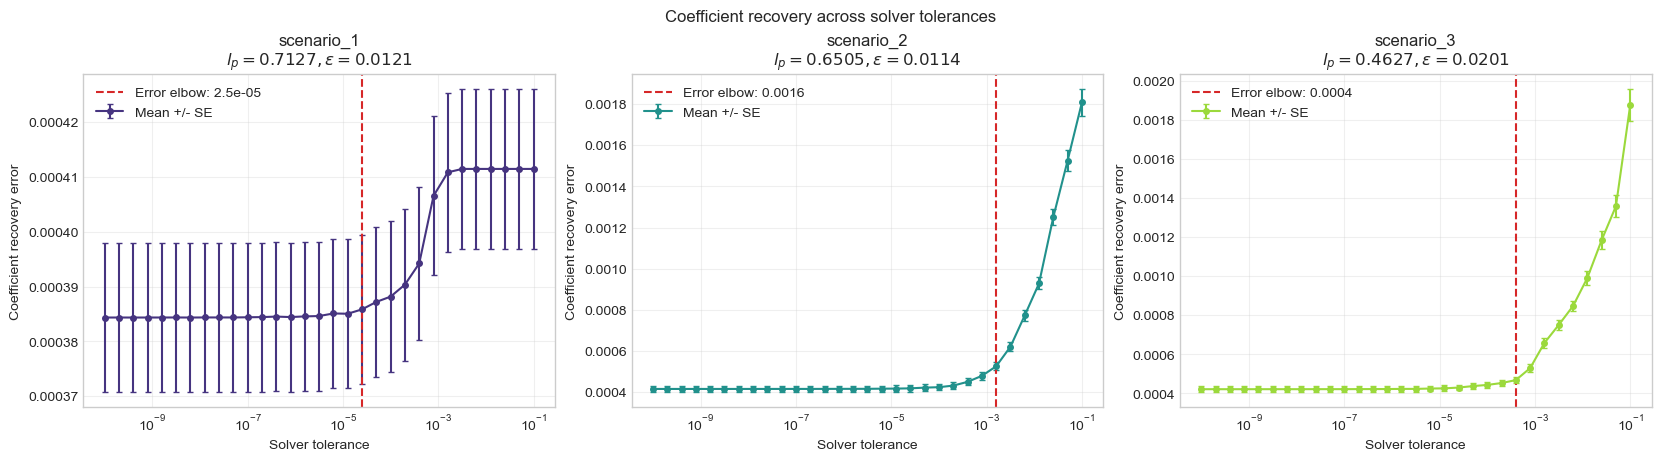

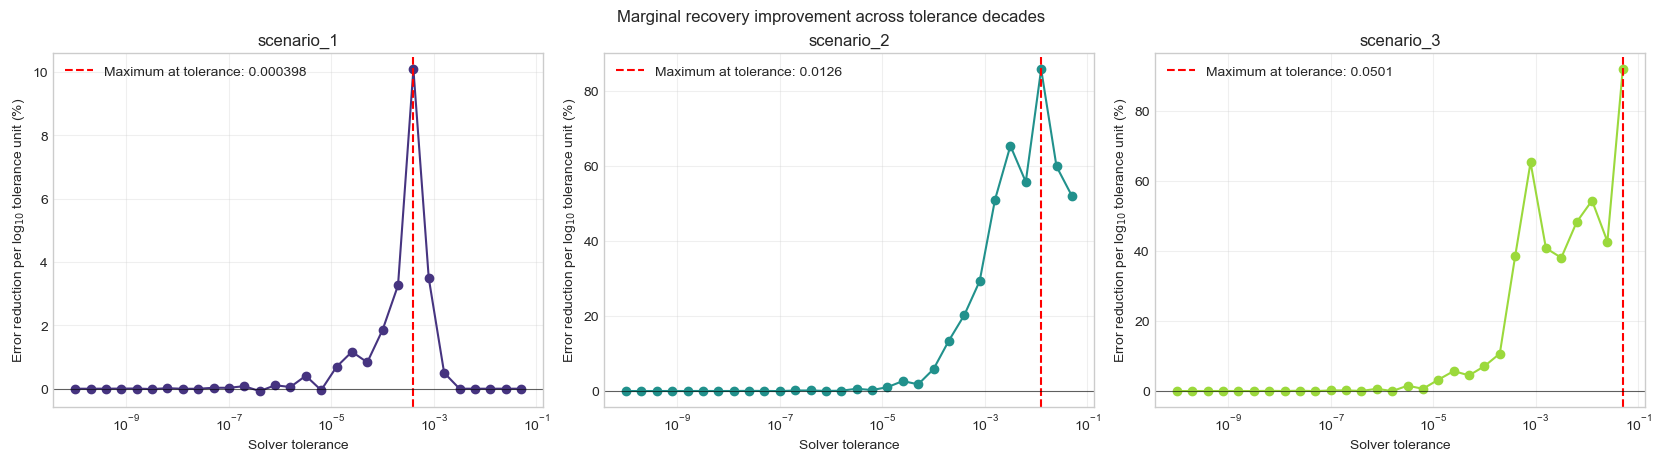

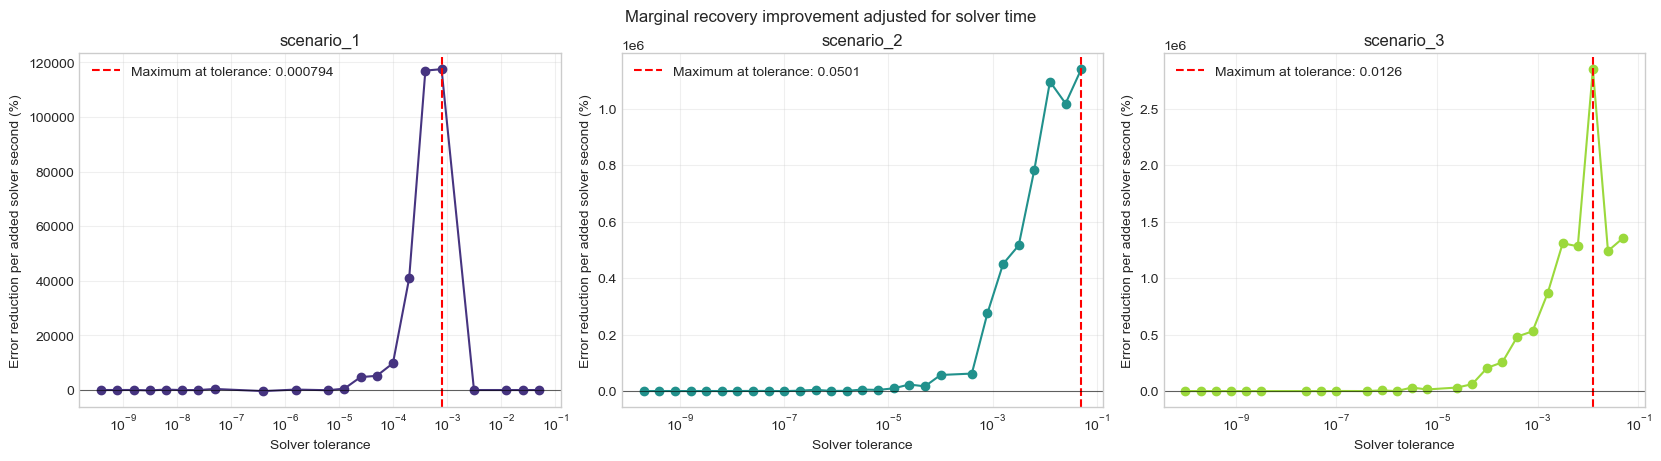

In [5]:
importlib.reload(tolerance_plot)
figures = tolerance_plot.plot_tolerance_tuning(output_path)
for figure in figures:
    display(figure)
    plt.close(figure)